# NBA player scoring — dataset inspection and starter analysis

Companion to `NBA_Project_Proposal_Revised.md`. First inspect the data, then prepare a small, leakage-aware baseline for **points in a player's upcoming appearance**.

**Execution status:** source documentation inspected on October 28, 2026; raw data analysis has **not** been executed in this environment. Python downloads failed because external hostnames could not be resolved, and `pyarrow` is not installed. No sample statistics or model results below are fabricated. Run all cells in a network-enabled Python environment to populate the outputs.

Sources: [Hugging Face dataset card](https://huggingface.co/datasets/cbratkovics/nba-game-logs), [season files](https://huggingface.co/datasets/cbratkovics/nba-game-logs/tree/main/game_logs). The general dataset viewer currently reports a schema error; use the season Parquet files explicitly instead of an unrestricted `load_dataset(...)` call.

## 1. Setup and reproducibility

From the project directory, install `requirements.txt` into your chosen environment (`python -m pip install -r requirements.txt`), then select that environment as this notebook's kernel. Downloads total approximately 2.13 MB for the six season files. Existing cached files are reused and validated against their recorded checksums.

The snapshot is pinned to the repository revision observed during inspection. Updating it is an intentional change: use a new revision and an empty cache directory. The notebook works when launched from either the repository root or `notebooks/`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})
ROOT = Path.cwd().resolve()
if not (ROOT / "NBA_Project_Proposal_Revised.md").exists():
    ROOT = ROOT.parent
assert (ROOT / "NBA_Project_Proposal_Revised.md").exists(), "Open from the project root or notebooks/."
DATASET_ID = "cbratkovics/nba-game-logs"
REVISION = "d70d239b7b82e3e4071d2c7caab2d0e39db70389"
SEASONS = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26", "2026-27"]
CACHE = ROOT / "data" / "raw" / REVISION
CACHE.mkdir(parents=True, exist_ok=True)
print({"project": str(ROOT), "dataset": DATASET_ID, "revision": REVISION})

{'project': '/Users/skar/Documents/Courses/Applied ML/nba_estimate', 'dataset': 'cbratkovics/nba-game-logs', 'revision': 'd70d239b7b82e3e4071d2c7caab2d0e39db70389'}


## 2. Documented fields and prediction-time meaning

These are the 26 fields listed in the dataset card, **not yet an observed schema**. The next sections compare them with the downloaded files, including physical types, missingness, and examples. Identifiers are kept as strings.

`pts` is the target on the row being predicted. Same-game `minutes` and all other box-score outcomes are only suitable as historical inputs after a lag. `source` is ingestion metadata, not a basketball predictor. No injury history, complete schedule, expected starters, or DNP labels are supplied in this schema.

In [2]:
FIELD_INFO = {
    "game_id": ("Game identifier", "identifier"),
    "game_date": ("Game date", "pregame context"),
    "season": ("Season label", "pregame context"),
    "player_id": ("Player identifier", "identifier"),
    "player_name": ("Player display name", "display only"),
    "team": ("Player team abbreviation", "pregame context"),
    "opponent": ("Opponent abbreviation", "pregame context"),
    "home": ("Home indicator; inspect its encoding", "pregame context"),
    "minutes": ("Minutes played", "lag only"),
    "pts": ("Points scored", "target / lag only"),
    "reb": ("Total rebounds", "lag only"),
    "ast": ("Assists", "lag only"),
    "fgm": ("Field goals made", "lag only"),
    "fga": ("Field goals attempted", "lag only"),
    "fg3m": ("Three-point field goals made", "lag only"),
    "fg3a": ("Three-point field goals attempted", "lag only"),
    "ftm": ("Free throws made", "lag only"),
    "fta": ("Free throws attempted", "lag only"),
    "oreb": ("Offensive rebounds", "lag only"),
    "dreb": ("Defensive rebounds", "lag only"),
    "stl": ("Steals", "lag only"),
    "blk": ("Blocks", "lag only"),
    "tov": ("Turnovers", "lag only"),
    "pf": ("Personal fouls", "lag only"),
    "plus_minus": ("On-court point differential", "lag only"),
    "source": ("Ingestion provenance", "audit only"),
}
field_dictionary = pd.DataFrame.from_dict(
    FIELD_INFO, orient="index", columns=["meaning", "prediction_role"]
).rename_axis("field")
display(field_dictionary)

,meaning,prediction_role
field,,
game_id,Game identifier,identifier
game_date,Game date,pregame context
season,Season label,pregame context
player_id,Player identifier,identifier
player_name,Player display name,display only
team,Player team abbreviation,pregame context
opponent,Opponent abbreviation,pregame context
home,Home indicator; inspect its encoding,pregame context
minutes,Minutes played,lag only


## 3. Download only the season game logs

Use standard HTTPS downloads plus pandas/pyarrow; the Hugging Face `datasets` package is unnecessary. A manifest records the exact paths, revision, download timestamps, and SHA-256 hashes. Download failures stop here with an actionable message; no synthetic fallback is used.

HTTPS downloads use the system trust store plus [certifi](https://github.com/certifi/python-certifi)'s CA bundle with certificate and hostname verification enabled. If upgrading an existing environment, run `%pip install --upgrade certifi` in a notebook cell before retrying. Errors now include the underlying TLS, HTTP, or network cause.


In [3]:
import ssl
import urllib.error

try:
    import certifi
    import pyarrow.parquet as pq
except ImportError as exc:
    raise ImportError("Install requirements.txt in this notebook's kernel environment, then rerun.") from exc

# Add a portable CA bundle for Python installations whose default trust store is incomplete.
# Preserve system trust and keep certificate and hostname verification enabled.
ssl_context = ssl.create_default_context()
ssl_context.load_verify_locations(cafile=certifi.where())

manifest_path = CACHE / "manifest.json"
manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {
    "dataset": DATASET_ID, "revision": REVISION, "files": {}
}
assert manifest["dataset"] == DATASET_ID and manifest["revision"] == REVISION

for season in SEASONS:
    name = f"game_logs_{season}.parquet"
    destination = CACHE / name
    url = f"https://huggingface.co/datasets/{DATASET_ID}/resolve/{REVISION}/game_logs/{name}"
    if not destination.exists():
        temporary = destination.with_suffix(".download")
        try:
            request = urllib.request.Request(url, headers={"User-Agent": "nba-course-project/0.1"})
            with urllib.request.urlopen(request, timeout=90, context=ssl_context) as response:
                temporary.write_bytes(response.read())
            pq.read_schema(temporary)  # Reject an HTML error or malformed file before caching.
            temporary.replace(destination)
        except Exception as exc:
            temporary.unlink(missing_ok=True)
            reason = getattr(exc, "reason", exc)
            if isinstance(reason, ssl.SSLCertVerificationError):
                guidance = (
                    "TLS certificate verification failed. In a notebook cell, run "
                    "`%pip install --upgrade certifi`, then rerun this cell. "
                    "If your network uses a private CA, configure SSL_CERT_FILE with "
                    "the CA bundle supplied by your network administrator before rerunning."
                )
            elif isinstance(exc, urllib.error.HTTPError):
                guidance = f"The server returned HTTP {exc.code}; check the dataset revision and file path."
            else:
                guidance = "Check DNS, network access, and proxy settings, then rerun this cell."
            raise RuntimeError(
                f"Could not download {url}.\n"
                f"Cause: {type(reason).__name__}: {reason}\n{guidance}"
            ) from exc
    digest = hashlib.sha256(destination.read_bytes()).hexdigest()
    previous = manifest["files"].get(name)
    if previous is not None:
        assert digest == previous["sha256"], f"Cache checksum changed: {name}"
    else:
        manifest["files"][name] = {
            "url": url, "sha256": digest, "bytes": destination.stat().st_size,
            "cached_at_utc": datetime.now(timezone.utc).isoformat(),
        }
    manifest_path.write_text(json.dumps(manifest, indent=2) + "\n")
display(pd.DataFrame.from_dict(manifest["files"], orient="index"))

,url,sha256,bytes,cached_at_utc
game_logs_2021-22.parquet,https://huggingface.co/datasets/cbratkovics/nb...,febba85ec9ad206f9e425e549535bdd657a66f6a72cbdf...,402836,2026-10-28T22:02:40.988929+00:00
game_logs_2022-23.parquet,https://huggingface.co/datasets/cbratkovics/nb...,f398a553e4c92216fc2dfc4d25622470c8a62bd8254811...,393440,2026-10-28T22:02:41.492894+00:00
game_logs_2023-24.parquet,https://huggingface.co/datasets/cbratkovics/nb...,5fff5e5a57dd73ea36b6610c61fb1cb182156ace89e5c8...,405025,2026-10-28T22:02:42.103281+00:00
game_logs_2024-25.parquet,https://huggingface.co/datasets/cbratkovics/nb...,a4cc538112a7c4c7a4f42476022726159907ed71fc13cd...,437754,2026-10-28T22:02:42.692396+00:00
game_logs_2025-26.parquet,https://huggingface.co/datasets/cbratkovics/nb...,2119a573915ebcd548a290e9d2d9c509921adb85b7e01e...,445819,2026-10-28T22:02:43.391429+00:00
game_logs_2026-27.parquet,https://huggingface.co/datasets/cbratkovics/nb...,3c2339a43834d639a7956902adc54048cb305cb3290eb1...,45166,2026-10-28T22:02:43.755906+00:00


In [4]:
frames, physical_schema = [], []
for season in SEASONS:
    path = CACHE / f"game_logs_{season}.parquet"
    schema = pq.read_schema(path)
    physical_schema.extend({"season_file": season, "field": f.name, "arrow_type": str(f.type)} for f in schema)
    part = pd.read_parquet(path, engine="pyarrow")
    missing_fields = set(FIELD_INFO) - set(part.columns)
    extra_fields = set(part.columns) - set(FIELD_INFO)
    assert not missing_fields, f"Missing fields in {season}: {missing_fields}"
    if extra_fields:
        print(f"Additional fields in {season}: {sorted(extra_fields)}")
    assert part["season"].eq(season).all(), f"Season/file mismatch: {season}"
    frames.append(part)
raw = pd.concat(frames, ignore_index=True)
physical_schema = pd.DataFrame(physical_schema)
display(physical_schema.pivot(index="field", columns="season_file", values="arrow_type"))
print(f"Loaded {len(raw):,} rows and {len(raw.columns)} columns")
display(raw.head(10))

season_file,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
field,,,,,,
ast,int64,int64,int64,int64,int64,int64
blk,int64,int64,int64,int64,int64,int64
dreb,int64,int64,int64,int64,int64,int64
fg3a,int64,int64,int64,int64,int64,int64
fg3m,int64,int64,int64,int64,int64,int64
fga,int64,int64,int64,int64,int64,int64
fgm,int64,int64,int64,int64,int64,int64
fta,int64,int64,int64,int64,int64,int64
ftm,int64,int64,int64,int64,int64,int64


Loaded 131,660 rows and 26 columns


,game_id,game_date,season,player_id,player_name,team,opponent,home,minutes,pts,reb,ast,fgm,fga,fg3m,fg3a,ftm,fta,oreb,dreb,stl,blk,tov,pf,plus_minus,source
0,0022100001,2021-10-19,2021-22,200746,LaMarcus Aldridge,BKN,MIL,False,15.0,1,3,1,0,2,0,0,1,4,0,3,0,1,1,2,2,kaggle_v515
1,0022100001,2021-10-19,2021-22,200794,Paul Millsap,BKN,MIL,False,5.0,0,3,0,0,0,0,0,0,0,1,2,0,1,1,0,-1,kaggle_v515
2,0022100001,2021-10-19,2021-22,201142,Kevin Durant,BKN,MIL,False,30.0,32,11,4,13,25,3,7,3,6,0,11,0,2,1,2,-20,kaggle_v515
3,0022100001,2021-10-19,2021-22,201572,Brook Lopez,MIL,BKN,True,28.0,8,5,0,3,9,2,4,0,0,2,3,1,3,0,3,0,kaggle_v515
4,0022100001,2021-10-19,2021-22,201588,George Hill,MIL,BKN,True,23.0,1,5,3,0,3,0,2,1,2,2,3,0,1,1,5,-6,kaggle_v515
5,0022100001,2021-10-19,2021-22,201933,Blake Griffin,BKN,MIL,False,22.0,6,5,0,2,5,0,1,2,2,1,4,1,0,1,1,-6,kaggle_v515
6,0022100001,2021-10-19,2021-22,201935,James Harden,BKN,MIL,False,30.0,20,8,8,6,16,4,8,4,4,3,5,1,2,4,3,-20,kaggle_v515
7,0022100001,2021-10-19,2021-22,201949,James Johnson,BKN,MIL,False,20.0,1,0,2,0,2,0,1,1,2,0,0,0,1,0,3,-6,kaggle_v515
8,0022100001,2021-10-19,2021-22,201950,Jrue Holiday,MIL,BKN,True,17.0,12,1,1,5,7,2,4,0,0,1,0,1,0,0,0,17,kaggle_v515
9,0022100001,2021-10-19,2021-22,201988,Patty Mills,BKN,MIL,False,29.0,21,2,2,7,11,7,7,0,0,0,2,1,1,0,1,7,kaggle_v515


## 4. Audit before cleaning

Preserve `raw` and create `df` separately. Do not silently drop duplicates, coerce invalid targets to zero, or interpret missing minutes as a DNP. Report anomalies before deciding whether to exclude them.

In [5]:
field_profile = pd.DataFrame({
    "pandas_dtype": raw.dtypes.astype(str),         # Data Types
    "missing_count": raw.isna().sum(),              # Number of missing values in a field
    "distinct_values": raw.nunique(dropna=True),    # Number of distinct values in a field
    "examples": [raw[c].dropna().astype(str).unique()[:3].tolist() for c in raw],
}).join(field_dictionary)
display(field_profile)
print("Exact duplicate rows:", raw.duplicated().sum())
print("Duplicate player/game keys:", raw.duplicated(["player_id", "game_id"]).sum())
display(raw[["home", "source"]].value_counts(dropna=False).rename("rows").reset_index())

,pandas_dtype,missing_count,distinct_values,examples,meaning,prediction_role
game_id,string,0,6198,"[0022100001, 0022100002, 0022100003]",Game identifier,identifier
game_date,datetime64[us],0,823,"[2021-10-19, 2021-10-20, 2021-10-21]",Game date,pregame context
season,string,0,6,"[2021-22, 2022-23, 2023-24]",Season label,pregame context
player_id,int64,0,1074,"[200746, 200794, 201142]",Player identifier,identifier
player_name,string,0,1079,"[LaMarcus Aldridge, Paul Millsap, Kevin Durant]",Player display name,display only
team,string,0,30,"[BKN, MIL, LAL]",Player team abbreviation,pregame context
opponent,string,0,30,"[MIL, BKN, GSW]",Opponent abbreviation,pregame context
home,bool,0,2,"[False, True]",Home indicator; inspect its encoding,pregame context
minutes,float64,0,3524,"[15.0, 5.0, 30.0]",Minutes played,lag only
pts,int64,0,68,"[1, 0, 32]",Points scored,target / lag only


Exact duplicate rows: 0
Duplicate player/game keys: 0


,home,source,rows
0,True,kaggle_v515,65396
1,False,kaggle_v515,65018
2,True,kaggle_daily,625
3,False,kaggle_daily,621


In [6]:
df = raw.copy()
for c in ["game_id", "player_id", "season", "team", "opponent"]:
    df[c] = df[c].astype("string")
df["game_date"] = pd.to_datetime(df["game_date"], errors="raise", utc=True).dt.tz_convert(None).dt.normalize()
BOX_STATS = ["minutes", "pts", "reb", "ast", "fgm", "fga", "fg3m", "fg3a",
             "ftm", "fta", "oreb", "dreb", "stl", "blk", "tov", "pf", "plus_minus"]
for c in BOX_STATS:
    df[c] = pd.to_numeric(df[c], errors="raise")
assert df[["game_id", "player_id", "season", "game_date", "team", "opponent"]].notna().all().all()
assert not df.duplicated(["player_id", "game_id"]).any(), "Resolve duplicate keys before continuing."
assert not df.duplicated(["player_id", "game_date"]).any(), "Date-only ordering is ambiguous for this player."
# Explicitly recognize documented common encodings; reject unfamiliar values.
home_mapping = {"true": True, "false": False, "1": True, "0": False, "1.0": True, "0.0": False}
normalized_home = df["home"].astype("string").str.lower().str.strip()
assert normalized_home.isin(home_mapping).all(), f"Inspect home values: {normalized_home.unique()}"
df["home"] = normalized_home.map(home_mapping).astype(bool)
df = df.sort_values(["player_id", "game_date", "game_id"]).reset_index(drop=True)

In [7]:
audit_flags = pd.DataFrame({
    "missing_target": df["pts"].isna(),
    "missing_minutes": df["minutes"].isna(),
    "nonpositive_minutes": df["minutes"].le(0),
    "negative_count_stat": df[[c for c in BOX_STATS if c != "plus_minus"]].lt(0).any(axis=1),
    "field_goals_made_gt_attempted": df["fgm"].gt(df["fga"]),
    "threes_made_gt_attempted": df["fg3m"].gt(df["fg3a"]),
    "free_throws_made_gt_attempted": df["ftm"].gt(df["fta"]),
    "three_attempts_gt_all_attempts": df["fg3a"].gt(df["fga"]),
    "rebounds_disagree": (df["reb"] - df["oreb"] - df["dreb"]).abs().gt(1e-8),
    "points_disagree": (df["pts"] - (2 * df["fgm"] + df["fg3m"] + df["ftm"])).abs().gt(1e-8),
    "same_team_and_opponent": df["team"].eq(df["opponent"]),
    "season_date_mismatch": df["game_date"].dt.year.sub(df["game_date"].dt.month.lt(7).astype(int)).ne(
        df["season"].str[:4].astype(int)),
})
display(audit_flags.sum().rename("flagged_rows").to_frame())
display(df.loc[audit_flags.any(axis=1)].head(20))
# Inspect flagged records and document any cleaning before fitting a model.
assert not audit_flags["missing_target"].any(), "Missing targets need an explicit exclusion policy."

,flagged_rows
missing_target,0.0
missing_minutes,0.0
nonpositive_minutes,0.0
negative_count_stat,0.0
field_goals_made_gt_attempted,0.0
threes_made_gt_attempted,0.0
free_throws_made_gt_attempted,0.0
three_attempts_gt_all_attempts,0.0
rebounds_disagree,0.0
points_disagree,0.0


,game_id,game_date,season,player_id,player_name,team,opponent,home,minutes,pts,reb,ast,fgm,fga,fg3m,fg3a,ftm,fta,oreb,dreb,stl,blk,tov,pf,plus_minus,source


## 5. Coverage and matchup structure

Inventory all seasons before choosing an evaluation period. Card-reported caveats: the latest season is partial; DNP rows are omitted; seven games are absent in 2024–25. These are source claims to compare with observed coverage, not computed findings. Counts alone cannot establish completeness: a separate official schedule is needed to identify absent games reliably.

In [8]:
coverage = df.groupby("season", observed=True).agg(
    player_games=("game_id", "size"), games=("game_id", "nunique"),
    players=("player_id", "nunique"), teams=("team", "nunique"),
    first_game=("game_date", "min"), last_game=("game_date", "max"),
)
display(coverage)
game_audit = df.groupby("game_id").agg(
    dates=("game_date", "nunique"), seasons=("season", "nunique"),
    teams=("team", "nunique"), opponents=("opponent", "nunique"),
    home_values=("home", "nunique"), player_rows=("player_id", "size"),
)
# First check: Number of non-unique game dates and seasons is 1. 2 games cannot share the same game ID across seasons
# Second check: There cannot be more than or less than 2 teams/opponents in a single match. Both of these teams/opponents need to be different and cannot be the same value
bad_games = game_audit.loc[
    game_audit[["dates", "seasons"]].ne(1).any(axis=1)
    | game_audit[["teams", "opponents", "home_values"]].ne(2).any(axis=1)
]
display(bad_games)
team_games = df[["game_id", "team", "opponent", "home"]].drop_duplicates()
# Identify any game record which is redundantly a reciprocal of another record based on the teams and opponents playing
reciprocal = team_games.merge(
    team_games, left_on=["game_id", "team", "opponent"],
    right_on=["game_id", "opponent", "team"], suffixes=("", "_other"), how="left", indicator=True,
)
print("Non-reciprocal team records:", ((reciprocal["_merge"] != "both") | reciprocal["home"].eq(reciprocal["home_other"])).sum())

,player_games,games,players,teams,first_game,last_game
season,,,,,,
2021-22,25826,1230,602,30,2021-10-19,2022-04-10
2022-23,25687,1230,539,30,2022-10-18,2023-04-09
2023-24,26095,1230,570,30,2023-10-24,2024-04-14
2024-25,26158,1223,569,30,2024-10-22,2025-04-13
2025-26,26648,1230,582,30,2025-10-21,2026-04-12
2026-27,1246,55,416,30,2026-10-20,2026-10-27


,dates,seasons,teams,opponents,home_values,player_rows
game_id,,,,,,


Non-reciprocal team records: 0


In [9]:
# Check the univariate statistics for number of players appearing in each game for each team
display(df.groupby(["game_id", "team"]).size().describe().rename("appearing_players_per_team_game"))

count    12396.000000
mean        10.621168
std          1.552341
min          6.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         15.000000
Name: appearing_players_per_team_game, dtype: float64

This shows a very reasonable distribution of the number of appearing players accounting for bench players and a reasonable standard deviation for the random variable

## 6. Player persistence, new arrivals, and season gaps

Following [the exploration plan](../plans/data_exploration.md), inspect participation **by player ID** before deciding how to split observations. Build a player-indexed summary with `num_seasons_played`, `taken_gap`, `starting_season_id`, and `season_played_mask`; then examine persistence, first observations, and returns after gaps.

A missing season means **no recorded appearance**, not proof that a player retired or was absent from the NBA. The first dataset season is left-censored, and 2026–27 is partial. “First observed” does not establish rookie status; confirming rookies requires career/debut data from before this dataset begins. These full-snapshot summaries use future participation and are for cohort analysis only, not pregame model inputs or eligibility decisions at an earlier cutoff.

In [10]:
# Chronological season IDs are zero-based positions in this dataset's observed season axis.
season_order = sorted(df["season"].dropna().unique(), key=lambda s: int(s[:4]))
season_ids = {season: i for i, season in enumerate(season_order)}
season_years = {season: int(season[:4]) for season in season_order}
assert all(b - a == 1 for a, b in zip(list(season_years.values())[:-1], list(season_years.values())[1:])), "Inspect missing entire seasons before computing masks."
season_axis = pd.DataFrame({"season_id": range(len(season_order)), "season": season_order})
season_axis["first_game"] = season_axis["season"].map(df.groupby("season")["game_date"].min())
season_axis["last_game"] = season_axis["season"].map(df.groupby("season")["game_date"].max())
display(season_axis)

# Count appearances, not duplicated names; a trade does not create another player.
player_season_games = pd.crosstab(df["player_id"], df["season"]).reindex(columns=season_order, fill_value=0)
player_season_presence = player_season_games.gt(0)
player_profiles = pd.DataFrame(index=player_season_presence.index)
player_profiles.index.name = "player_id"
latest_names = df.sort_values("game_date").drop_duplicates("player_id", keep="last").set_index("player_id")["player_name"]
player_profiles["player_name"] = latest_names.reindex(player_profiles.index)
player_profiles["num_seasons_played"] = player_season_presence.sum(axis=1)
player_profiles["starting_season"] = player_season_presence.idxmax(axis=1)
player_profiles["ending_season"] = player_season_presence.iloc[:, ::-1].idxmax(axis=1)
player_profiles["starting_season_id"] = player_profiles["starting_season"].map(season_ids)
player_profiles["ending_season_id"] = player_profiles["ending_season"].map(season_ids)
player_profiles["num_missing_seasons_between"] = (
    player_profiles["ending_season_id"] - player_profiles["starting_season_id"] + 1
    - player_profiles["num_seasons_played"]
)
player_profiles["taken_gap"] = player_profiles["num_missing_seasons_between"].gt(0)
# Leftmost character corresponds to the earliest season in season_axis; keep as a string.
player_profiles["season_played_mask"] = player_season_presence.astype(int).astype(str).agg("".join, axis=1)
player_profiles["all_observed_seasons"] = player_season_presence.all(axis=1)
player_profiles["player_games"] = player_season_games.sum(axis=1)
player_profiles["history_group"] = np.select(
    [player_profiles["all_observed_seasons"], player_profiles["taken_gap"], player_profiles["num_seasons_played"].eq(1)],
    ["All observed seasons", "Gap between observed seasons", "One observed season"],
    default="Consecutive subset of seasons",
)
assert player_profiles.index.is_unique
assert player_profiles["player_games"].sum() == len(df)
assert player_profiles["num_missing_seasons_between"].ge(0).all()
display(player_profiles.head(15))

,season_id,season,first_game,last_game
0,0,2021-22,2021-10-19,2022-04-10
1,1,2022-23,2022-10-18,2023-04-09
2,2,2023-24,2023-10-24,2024-04-14
3,3,2024-25,2024-10-22,2025-04-13
4,4,2025-26,2025-10-21,2026-04-12
5,5,2026-27,2026-10-20,2026-10-27


,player_name,num_seasons_played,starting_season,ending_season,starting_season_id,ending_season_id,num_missing_seasons_between,taken_gap,season_played_mask,all_observed_seasons,player_games,history_group
player_id,,,,,,,,,,,,
101108,Chris Paul,5,2021-22,2025-26,0,4,0,False,111110,False,278,Consecutive subset of seasons
101139,CJ Miles,1,2021-22,2021-22,0,0,0,False,100000,False,1,One observed season
101150,Lou Williams,1,2021-22,2021-22,0,0,0,False,100000,False,56,One observed season
1626143,Jahlil Okafor,1,2024-25,2024-25,3,3,0,False,000100,False,1,One observed season
1626144,Emmanuel Mudiay,1,2021-22,2021-22,0,0,0,False,100000,False,2,One observed season
1626145,Tyus Jones,6,2021-22,2026-27,0,5,0,False,111111,True,370,All observed seasons
1626147,Justin Anderson,1,2021-22,2021-22,0,0,0,False,100000,False,16,One observed season
1626149,Montrezl Harrell,2,2021-22,2022-23,0,1,0,False,110000,False,128,Consecutive subset of seasons
1626153,Delon Wright,4,2021-22,2024-25,0,3,0,False,111100,False,214,Consecutive subset of seasons


### 6.1 How much multi-season history is available?

Compare all observed seasons with the earlier snapshot excluding the latest, partial season. Requiring participation in 2026–27 would select players who have already appeared in a very short observation window. A single-season player may still support a chronological **within-season** split; a short history does not automatically make the player unusable.

,players
num_seasons_played,
1,330
2,178
3,153
4,117
5,111
6,185


,players,player_games,median_seasons,mean_seasons,player_percent
history_group,,,,,
All observed seasons,185,56184,6.0,6.000000,17.225326
Consecutive subset of seasons,510,65495,3.0,3.292157,47.486034
Gap between observed seasons,49,5167,3.0,3.244898,4.562384
One observed season,330,4814,1.0,1.000000,30.726257


,scope,seasons,players_seen,players_in_every_season
0,All observed seasons (latest is partial),6,1074,185
1,Exclude latest partial season,5,1027,249


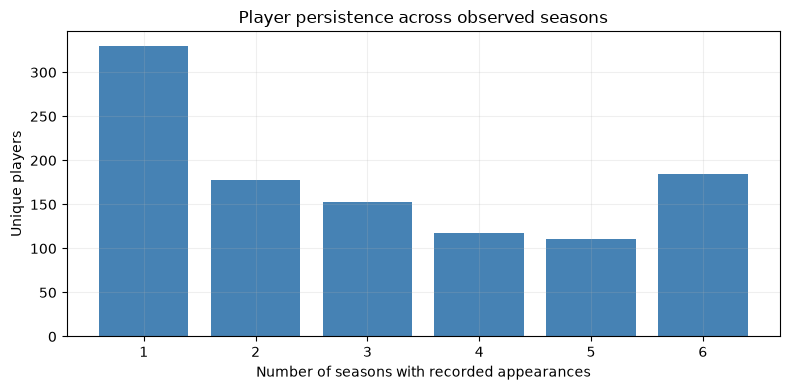

In [12]:
persistence_counts = player_profiles["num_seasons_played"].value_counts().reindex(range(1, len(season_order) + 1), fill_value=0).sort_index()
persistence_counts.index.name = "num_seasons_played"
display(persistence_counts.rename("players").to_frame())
cohort_summary = player_profiles.groupby("history_group").agg(
    players=("num_seasons_played", "size"), player_games=("player_games", "sum"),
    median_seasons=("num_seasons_played", "median"), mean_seasons=("num_seasons_played" ,"mean")
)
cohort_summary["player_percent"] = cohort_summary["players"].div(len(player_profiles)).mul(100)
display(cohort_summary)
prior_presence = player_season_presence.iloc[:, :-1]
persistence_sensitivity = pd.DataFrame([
    {"scope": "All observed seasons (latest is partial)", "seasons": len(season_order),
     "players_seen": len(player_profiles), "players_in_every_season": int(player_season_presence.all(axis=1).sum())},
    {"scope": "Exclude latest partial season", "seasons": prior_presence.shape[1],
     "players_seen": int(prior_presence.any(axis=1).sum()), "players_in_every_season": int(prior_presence.all(axis=1).sum())},
])
display(persistence_sensitivity)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(persistence_counts.index, persistence_counts.values, color="steelblue")
ax.set(title="Player persistence across observed seasons", xlabel="Number of seasons with recorded appearances", ylabel="Unique players")
ax.set_xticks(persistence_counts.index)
plt.tight_layout()
plt.show()

### 6.2 Retention, first observations, and returns

For each season, partition its players into first observed in the dataset, present in the immediately preceding season, or returning after at least one missing season. Retention is the intersection divided by **previous-season players**. The first season has no prior observation window, so its retention and departures are undefined. Latest-season absences remain provisional. Not plotting for season 2021-2022 since the data for player retention does not make sense there

,players,first_observed,retained_from_previous,returning_after_gap,previous_players_not_observed,retention_percent
season,,,,,,
2021-22,602,602,0,0,NaN,NaN
2022-23,539,106,433,0,169.0,71.926910
2023-24,570,108,449,13,90.0,83.302412
2024-25,569,107,447,15,123.0,78.421053
2025-26,582,104,464,14,105.0,81.546573
2026-27,416,47,362,7,220.0,62.199313


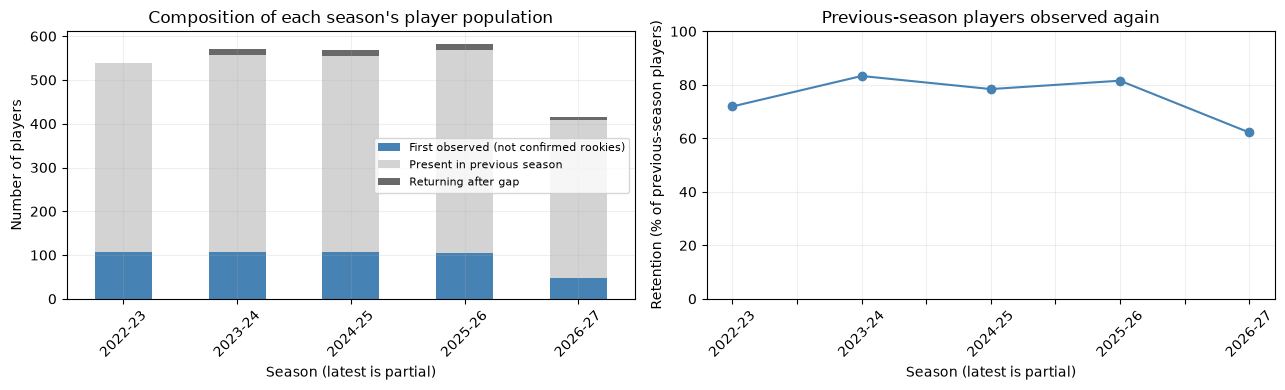

In [15]:
season_player_sets = {season: set(player_season_presence.index[player_season_presence[season]]) for season in season_order}
seen_before, previous_players, participation_rows = set(), set(), []
for i, season in enumerate(season_order):
    current_players = season_player_sets[season]
    retained = current_players & previous_players
    first_seen = current_players - seen_before
    returning = (current_players & seen_before) - previous_players
    participation_rows.append({
        "season": season, "players": len(current_players),
        "first_observed": len(first_seen), "retained_from_previous": len(retained),
        "returning_after_gap": len(returning),
        "previous_players_not_observed": len(previous_players - current_players) if i else np.nan,
        "retention_percent": 100 * len(retained) / len(previous_players) if previous_players else np.nan,
    })
    assert len(first_seen) + len(retained) + len(returning) == len(current_players)
    seen_before |= current_players
    previous_players = current_players
season_participation = pd.DataFrame(participation_rows).set_index("season")
display(season_participation)
assert season_participation["first_observed"].sum() == len(player_profiles)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
season_participation[["first_observed", "retained_from_previous", "returning_after_gap"]][1:].rename(columns={
    "first_observed": "First observed (not confirmed rookies)",
    "retained_from_previous": "Present in previous season", "returning_after_gap": "Returning after gap",
}).plot.bar(stacked=True, ax=axes[0], color=["steelblue", "lightgray", "dimgray"])
axes[0].set(title="Composition of each season's player population", xlabel="Season (latest is partial)", ylabel="Number of players")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(fontsize=8)
season_participation["retention_percent"].iloc[1:].plot(marker="o", ax=axes[1], color="steelblue")
axes[1].set(title="Previous-season players observed again", xlabel="Season (latest is partial)", ylabel="Retention (% of previous-season players)", ylim=(0, 100))
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 6.3 Participation masks and gap examples

Masks make missing seasons explicit rather than assuming that every player appears between their first and last observation. Display common masks and a small deterministic sample of each history group; the latest recorded name is a display label only.

,season_played_mask,num_seasons_played,taken_gap,players
39,111111,6,False,185
21,100000,1,False,151
38,111110,5,False,64
33,111000,3,False,60
1,000010,1,False,56
29,110000,2,False,56
6,000111,3,False,49
2,000011,2,False,48
36,111100,4,False,47
0,000001,1,False,47


,player_name,num_seasons_played,starting_season,ending_season,starting_season_id,ending_season_id,num_missing_seasons_between,taken_gap,season_played_mask,all_observed_seasons,player_games,history_group
player_id,,,,,,,,,,,,
1630536,Sharife Cooper,2,2021-22,2025-26,0,4,3,True,100010,False,53,Gap between observed seasons
1630286,Trevon Scott,2,2021-22,2025-26,0,4,3,True,100010,False,8,Gap between observed seasons
1628366,Lonzo Ball,3,2021-22,2025-26,0,4,2,True,100110,False,105,Gap between observed seasons
203901,Elfrid Payton,2,2021-22,2024-25,0,3,2,True,100100,False,71,Gap between observed seasons
1631113,Kennedy Chandler,2,2022-23,2025-26,1,4,2,True,010010,False,45,Gap between observed seasons
1630585,Marcus Garrett,2,2021-22,2024-25,0,3,2,True,100100,False,15,Gap between observed seasons
1631211,Trevor Keels,2,2022-23,2025-26,1,4,2,True,010010,False,10,Gap between observed seasons
1627777,Georges Niang,5,2021-22,2026-27,0,5,1,True,111101,False,319,Gap between observed seasons
1630180,Saddiq Bey,5,2021-22,2026-27,0,5,1,True,111011,False,297,Gap between observed seasons


season,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
player_id,,,,,,
1630536,12,0,0,0,41,0
1630286,2,0,0,0,6,0
1628366,35,0,0,35,35,0
203901,49,0,0,22,0,0
1631113,0,34,0,0,11,0
1630585,12,0,0,3,0,0
1631211,0,2,0,0,8,0
1627777,76,78,82,79,0,4
1630180,82,77,63,0,72,3


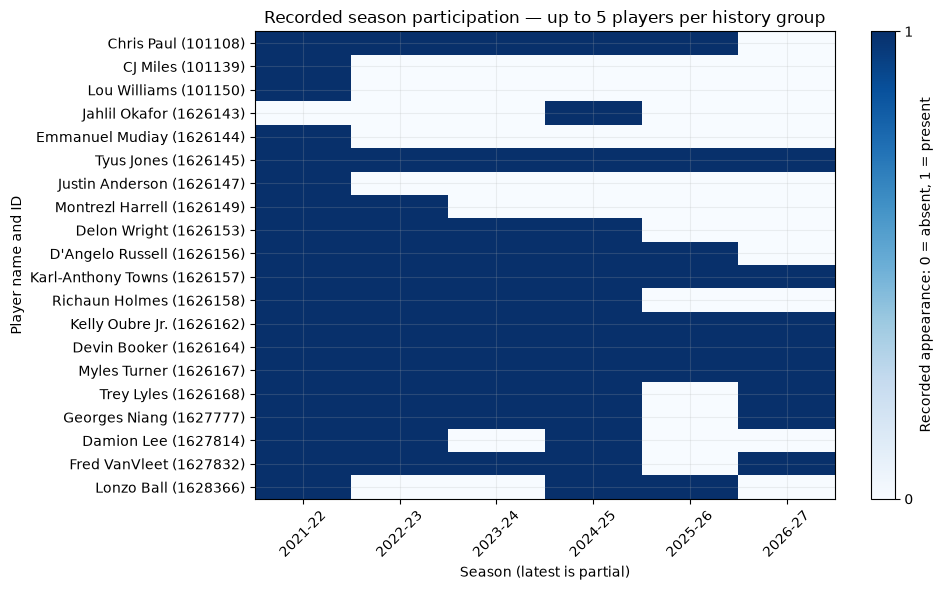

In [ ]:
participation_patterns = player_profiles.groupby(["season_played_mask", "num_seasons_played", "taken_gap"]).size().rename("players").reset_index().sort_values("players", ascending=False)
display(participation_patterns.head(20))
gap_examples = player_profiles.loc[player_profiles["taken_gap"]].sort_values(
    ["num_missing_seasons_between", "player_games"], ascending=False
)
display(gap_examples.head(15))
if not gap_examples.empty:
    display(player_season_games.loc[gap_examples.head(10).index])

sample_profiles = player_profiles.sort_index().groupby("history_group", sort=True).head(5)
fig, ax = plt.subplots(figsize=(10, max(3, 0.3 * len(sample_profiles))))
image = ax.imshow(player_season_presence.loc[sample_profiles.index].astype(int), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(season_order)), season_order, rotation=45)
ax.set_yticks(range(len(sample_profiles)), [f"{r.player_name} ({pid})" for pid, r in sample_profiles.iterrows()])
ax.set(title="Recorded season participation — up to 5 players per history group", xlabel="Season (latest is partial)", ylabel="Player name and ID")
fig.colorbar(image, ax=ax, ticks=[0, 1], label="Recorded appearance: 0 = absent, 1 = present")
plt.tight_layout()
plt.show()

In [ ]:
boundary_rows, historical_players = [], set()
for earlier, later in zip(season_order[:-1], season_order[1:]):
    historical_players |= season_player_sets[earlier]
    later_players = season_player_sets[later]
    seen = later_players & historical_players
    boundary_rows.append({
        "earlier_seasons_through": earlier, "later_season": later,
        "later_season_players": len(later_players), "seen_in_earlier_history": len(seen),
        "first_observed_later": len(later_players - historical_players),
        "returning_after_gap": len(seen - season_player_sets[earlier]),
        "seen_player_percent": 100 * len(seen) / len(later_players) if later_players else np.nan,
    })
boundary_diagnostics = pd.DataFrame(boundary_rows)
display(boundary_diagnostics)
print(f"{len(player_profiles):,} unique players across {len(season_order)} observed seasons.")
print(f"{player_profiles['all_observed_seasons'].sum():,} appear in every observed season; "
      f"{player_profiles['taken_gap'].sum():,} have an internal season gap.")

1,074 unique players across 6 observed seasons.
185 appear in every observed season; 49 have an internal season gap.
Next: choose the forecasting population and common time cutoffs, then compare errors by history group.


,earlier_seasons_through,later_season,later_season_players,seen_in_earlier_history,first_observed_later,returning_after_gap,seen_player_percent
0,2021-22,2022-23,539,433,106,0,80.333952
1,2022-23,2023-24,570,462,108,13,81.052632
2,2023-24,2024-25,569,462,107,15,81.195079
3,2024-25,2025-26,582,478,104,14,82.130584
4,2025-26,2026-27,416,369,47,7,88.701923


## 7. Basic MLR experiment design

For each observed player-game, compare three ordinary multiple linear regression (MLR) models:

1. Predict game points per minute (PPM) from that player's earlier game history.
2. Predict minutes from that player's earlier game history.
3. Predict points directly from the same pregame features.

Combine the first two predictions as `predicted_ppm * predicted_minutes`, then compare that result with direct predicted points on exactly the same held-out rows. Actual target-game minutes are used to define training/evaluation targets, never as input features.

Four expanding-history experiments use these outer train → test seasons:

- 2021–22 → 2022–23
- 2021–22 through 2022–23 → 2023–24
- 2021–22 through 2023–24 → 2024–25
- 2021–22 through 2024–25 → 2025–26

The partial 2026–27 season is excluded. Models are pooled across players, using **same-player historical features**, not a numeric player ID. Player IDs remain the index for coverage and split audits. Section 6's full-snapshot participation masks and gap summaries are not model features.

### 7.1 Targets, eligibility, and feature definitions

The modeling population is recorded appearances with finite points, positive finite minutes, and at least one prior valid appearance. The first observed appearance per player has no usable history and is excluded explicitly. No DNP rows or artificial zero-scoring games are added. These forecasts are conditional on the player appearing, not unconditional forecasts of availability.

Features include prior 5/10-appearance mean **per-game PPM** and minutes; previous-season means; season-to-date means; home/away; days since the last observed valid appearance; and prior appearance counts. PPM averages here are arithmetic means of game-level rates, not total points divided by total minutes. Rolling windows cross season boundaries and gaps using actual appearances only; their history counts and appearance-gap feature make the amount/age of history visible. A 5/10-game mean requires a full window, with missing values handled later using training-only imputation.

Previous-season features refer to the immediately preceding calendar season. If that season is missing for a player, the feature remains missing. Season-to-date means reset each season and exclude the current game. Starting/bench status cannot be recovered from the available fields; it is omitted until a reliable pregame source is available. Same-game box-score outcomes, actual starters/participants, and future participation information are excluded from the feature matrix.

### 7.2 Nested box-score feature sets

All additional inputs are the player's **shifted historical** statistics, never target-game assists, rebounds, steals, or other outcomes:

- `core`: the original 12 PPM/minutes/context features.
- `role_defense`: core plus prior 5-game assists, rebounds, steals, blocks, turnovers, and personal fouls (18 inputs).
- `shooting`: the preceding set plus prior 5-game field goals, three-pointers, and free throws made/attempted (24 inputs).
- `full_history`: core plus 5-game, 10-game, season-to-date, and previous-season means for all 15 box-score fields, including offensive/defensive rebounds and plus/minus (72 inputs before imputation indicators).

Counts shown by the code are authoritative. Nested sets are compared on the same eligible player-games; missing histories do not change row eligibility. Shooting counts are added first instead of noisy shooting percentages for zero-attempt games. The full set deliberately exposes redundancy: total rebounds are the sum of offensive and defensive rebounds, and shooting outcomes are related to scoring. Different rolling windows also overlap heavily. A lag makes these legitimate predictors, but does not remove multicollinearity. For every rolling mean, a full window of nonmissing values is required; expanding/previous-season means use available prior values.

There is no universal number of features that makes MLR too complex. Look for reduced training error without validation improvement, loss of design rank, large condition numbers, redundant predictors, and coefficient sensitivity across chronological fits. Those patterns motivate removing redundant features or a later regularized linear comparison before concluding that nonlinear models are needed.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

TARGET_COLUMNS = ["ppm_target", "minutes_target", "points_target"]
CORE_FEATURE_COLUMNS = [
    "home", "days_since_prior_appearance", "prior_appearances", "prior_season_appearances",
    "ppm_ma_5", "ppm_ma_10", "minutes_ma_5", "minutes_ma_10",
    "ppm_previous_season", "minutes_previous_season",
    "ppm_season_to_date", "minutes_season_to_date",
]


# Nested feature sets keep the comparison interpretable and use identical rows.
BOX_HISTORY_STATS = ["ast", "reb", "stl", "blk", "tov", "pf", "fgm", "fga",
                     "fg3m", "fg3a", "ftm", "fta", "oreb", "dreb", "plus_minus"]
ROLE_STATS = ["ast", "reb", "stl", "blk", "tov", "pf"]
SHOOTING_STATS = ["fgm", "fga", "fg3m", "fg3a", "ftm", "fta"]
FEATURE_SETS = {
    "core": CORE_FEATURE_COLUMNS,
    "role_defense": CORE_FEATURE_COLUMNS + [f"{stat}_ma_5" for stat in ROLE_STATS],
    "shooting": CORE_FEATURE_COLUMNS + [f"{stat}_ma_5" for stat in ROLE_STATS + SHOOTING_STATS],
    "full_history": CORE_FEATURE_COLUMNS + [
        f"{stat}_{history}" for stat in BOX_HISTORY_STATS
        for history in ["ma_5", "ma_10", "season_to_date", "previous_season"]
    ],
}
MLR_FEATURE_COLUMNS = list(dict.fromkeys(column for columns in FEATURE_SETS.values() for column in columns))
for columns in FEATURE_SETS.values():
    assert len(columns) == len(set(columns))
for simpler, larger in zip(list(FEATURE_SETS.values())[:-1], list(FEATURE_SETS.values())[1:]):
    assert set(simpler).issubset(larger)

def build_mlr_features(game_rows):
    data = game_rows.copy()
    required = ["player_id", "game_id", "game_date", "season", "home", "pts", "minutes"]
    assert data[required].notna().all().all(), "Resolve missing identifiers, dates, or targets first."
    assert not data.duplicated(["player_id", "game_id"]).any()
    data["game_date"] = pd.to_datetime(data["game_date"], utc=True).dt.tz_convert(None).dt.normalize()
    assert not data.duplicated(["player_id", "game_date"]).any(), "Need tipoff timestamps to order same-day appearances."
    for stat in BOX_HISTORY_STATS:
        data[stat] = pd.to_numeric(data[stat], errors="raise")
        # Missing historical box-score values are retained for training-only imputation.
        data[stat] = data[stat].replace([np.inf, -np.inf], np.nan)
    data["pts"] = pd.to_numeric(data["pts"], errors="raise")
    data["minutes"] = pd.to_numeric(data["minutes"], errors="raise")
    valid = (np.isfinite(data["pts"]) & data["pts"].ge(0)
             & np.isfinite(data["minutes"]) & data["minutes"].gt(0))
    excluded_invalid = int((~valid).sum())
    data = data.loc[valid].sort_values(["player_id", "game_date", "game_id"]).reset_index(drop=True)
    assert len(data), "No valid modeling rows."
    data["season_start"] = data["season"].str[:4].astype(int)
    data["ppm_target"] = data["pts"] / data["minutes"]
    data["minutes_target"] = data["minutes"]
    data["points_target"] = data["pts"]
    assert np.isfinite(data[TARGET_COLUMNS]).all().all(), "Inspect nonfinite target rates."

    by_player = data.groupby("player_id", sort=False)
    data["prior_appearances"] = by_player.cumcount()
    data["prior_appearance_date"] = by_player["game_date"].shift(1)
    data["days_since_prior_appearance"] = (data["game_date"] - data["prior_appearance_date"]).dt.days
    known = data["prior_appearance_date"].notna()
    assert (data.loc[known, "prior_appearance_date"] < data.loc[known, "game_date"]).all()
    by_player_season = data.groupby(["player_id", "season"], sort=False)
    data["prior_season_appearances"] = by_player_season.cumcount()
    history_sources = [("ppm_target", "ppm"), ("minutes_target", "minutes")]
    history_sources += [(stat, stat) for stat in BOX_HISTORY_STATS]
    history_columns = {}
    for target, prefix in history_sources:
        for window in [5, 10]:
            history_columns[f"{prefix}_ma_{window}"] = by_player[target].transform(
                lambda values: values.shift(1).rolling(window, min_periods=window).mean()
            )
        history_columns[f"{prefix}_season_to_date"] = by_player_season[target].transform(
            lambda values: values.shift(1).expanding(min_periods=1).mean()
        )

    # Batch new columns to avoid repeatedly fragmenting the DataFrame.
    data = pd.concat([data, pd.DataFrame(history_columns, index=data.index)], axis=1)
    previous = data.groupby(["player_id", "season_start"], as_index=False).agg(**{
        f"{prefix}_previous_season": (target, "mean") for target, prefix in history_sources
    })
    previous["season_start"] += 1
    data = data.merge(previous, on=["player_id", "season_start"], how="left", validate="many_to_one")
    assert data.loc[data["prior_season_appearances"].eq(0), ["ppm_season_to_date", "minutes_season_to_date"]].isna().all().all()
    assert not set(MLR_FEATURE_COLUMNS) & set(TARGET_COLUMNS + ["pts", "minutes", "player_id", *BOX_HISTORY_STATS])
    data["model_eligible"] = data["prior_appearances"].gt(0)
    quality = pd.Series({
        "input_rows": len(game_rows), "excluded_invalid_targets": excluded_invalid,
        "excluded_no_prior_appearance": int((~data["model_eligible"]).sum()),
        "eligible_rows": int(data["model_eligible"].sum()),
    }, name="rows")
    return data, quality

In [ ]:
# Run when ready: df comes from the earlier cleaning/audit sections.
mlr_data, mlr_quality = build_mlr_features(df)
display(mlr_quality.to_frame())
display(mlr_data.groupby("season").agg(
    valid_appearances=("game_id", "size"), eligible_appearances=("model_eligible", "sum"),
    players=("player_id", "nunique"),
))
display(mlr_data.loc[mlr_data["model_eligible"], MLR_FEATURE_COLUMNS].isna().mean().rename("missing_fraction").to_frame())
display(mlr_data[["player_id", "player_name", "season", "game_date", *TARGET_COLUMNS, *MLR_FEATURE_COLUMNS]].head(15))

feature_set_overview = pd.DataFrame([
    {"feature_set": name, "input_features": len(columns)} for name, columns in FEATURE_SETS.items()
])
display(feature_set_overview)

## 8. Chronological experiments and player-indexed split audits

The requested whole-season tests fix the outer boundaries; their train/test fractions will not generally be 80/20. Inside each experiment's historical training seasons, choose a **shared date cutoff** giving the nearest available 80/20 split by eligible player-game rows. Dates are kept intact. The earlier part is inner training and the later part is validation; each player's actual fraction is reported, not forced to equal 80/20. Separate player-specific cutoffs would mix future training observations with earlier validation observations in a pooled model.

After validation, fit each fixed model on all historical training seasons and evaluate the specified later test season. During validation/test, features for a later game may use outcomes from completed earlier games in that held-out period. The fitted coefficients and preprocessing remain frozen. This is a sequential walk-forward feature evaluation, not an entire season forecast made on opening day.

Returning players keep earlier observed history; missing seasons create no rows. Eligibility is not restricted to players appearing in every season. “Seen” status uses only the corresponding fit period; first-observed players with at least one earlier appearance in the evaluation period can still receive pooled-model predictions. First appearances excluded for lack of history are reported separately above. No full-snapshot persistence filter is applied.

In [ ]:
EXPERIMENTS = [
    {"name": "E1", "train_seasons": ["2021-22"], "test_season": "2022-23"},
    {"name": "E2", "train_seasons": ["2021-22", "2022-23"], "test_season": "2023-24"},
    {"name": "E3", "train_seasons": ["2021-22", "2022-23", "2023-24"], "test_season": "2024-25"},
    {"name": "E4", "train_seasons": ["2021-22", "2022-23", "2023-24", "2024-25"], "test_season": "2025-26"},
]
INNER_TRAIN_FRACTION = 0.80

def make_mlr_splits(data, experiment, train_fraction=INNER_TRAIN_FRACTION):
    assert 0 < train_fraction < 1
    history = data.loc[data["season"].isin(experiment["train_seasons"]) & data["model_eligible"]].copy()
    test = data.loc[data["season"].eq(experiment["test_season"]) & data["model_eligible"]].copy()
    assert not history.empty and not test.empty, f"Missing eligible data for {experiment['name']}"
    assert history["game_date"].max() < test["game_date"].min()
    daily_counts = history.groupby("game_date").size().sort_index()
    assert len(daily_counts) >= 2, "Need at least two historical dates for validation."
    cumulative = daily_counts.cumsum().iloc[:-1]  # Leave at least one validation date.
    cutoff = (cumulative / len(history) - train_fraction).abs().idxmin()
    inner_train = history.loc[history["game_date"].le(cutoff)].copy()
    validation = history.loc[history["game_date"].gt(cutoff)].copy()
    assert inner_train["game_date"].max() < validation["game_date"].min()
    assert validation["game_date"].max() < test["game_date"].min()
    assert set(inner_train.index).isdisjoint(validation.index)
    assert set(history.index).isdisjoint(test.index)
    # A player's missing seasons and shorter history remain visible in this audit.
    counts = pd.concat({
        "inner_train_rows": inner_train.groupby("player_id").size(),
        "validation_rows": validation.groupby("player_id").size(),
        "outer_train_rows": history.groupby("player_id").size(),
        "test_rows": test.groupby("player_id").size(),
    }, axis=1).fillna(0).astype(int).rename_axis("player_id")
    counts["inner_train_fraction"] = counts["inner_train_rows"].div(counts["outer_train_rows"].replace(0, np.nan))
    counts["outer_train_fraction"] = counts["outer_train_rows"].div(counts["outer_train_rows"] + counts["test_rows"])
    counts["seen_in_outer_training"] = counts["outer_train_rows"].gt(0)
    summary = {
        "experiment": experiment["name"], "test_season": experiment["test_season"],
        "validation_cutoff": cutoff, "inner_train_rows": len(inner_train), "validation_rows": len(validation),
        "inner_train_fraction": len(inner_train) / len(history),
        "outer_train_rows": len(history), "test_rows": len(test),
        "outer_train_fraction": len(history) / (len(history) + len(test)),
        "test_players": test["player_id"].nunique(),
        "test_players_unseen_in_outer_training": len(set(test["player_id"]) - set(history["player_id"])),
    }
    return {"history": history, "inner_train": inner_train, "validation": validation,
            "test": test, "player_counts": counts, "summary": summary}

In [ ]:
mlr_splits = {experiment["name"]: make_mlr_splits(mlr_data, experiment) for experiment in EXPERIMENTS}
split_overview = pd.DataFrame([split["summary"] for split in mlr_splits.values()])
display(split_overview)
player_split_audits = pd.concat({name: split["player_counts"] for name, split in mlr_splits.items()}, names=["experiment", "player_id"])
display(player_split_audits.head(20))
display(player_split_audits.groupby(level="experiment")[["inner_train_fraction", "outer_train_fraction"]].describe())
# Inspect one player across all experiments by ID, e.g.:
# display(player_split_audits.xs("2544", level="player_id"))

## 9. Three MLR models and comparison metrics

Each target receives its own pipeline: training-only median imputation with missingness indicators, standardization, and ordinary least-squares `LinearRegression`. Entirely missing training columns are retained as zero-filled columns. Each of the four nested feature sets receives the same three unregularized OLS models; no hyperparameter tuning is performed yet. Report rank and coefficients to inspect redundancy among overlapping history features; standardization changes coefficient units, not the model's linear form.

Primary predictions remain **unclipped** to reveal negative or otherwise implausible OLS outputs. Report those rates explicitly. No upper bound on minutes is imposed because overtime is possible. A later experiment can compare nonnegative alternatives, with the choice made on validation data.

Compare MAE and RMSE for PPM and minutes individually, and direct versus factorized points. Include a prior 5-game points average as a simple baseline. The learned models use the same eligible rows; baseline metrics also use the intersection where that rolling baseline exists, with a separate shared-row comparison so missing windows do not distort the ranking.

**Covariance interpretation:** `E[PPM × minutes | X] = E[PPM | X] × E[minutes | X] + Cov(PPM, minutes | X)`. Agreement between the factorized and direct models does not establish low conditional covariance. Held-out rate/minutes residual correlation, covariance, and mean residual product are descriptive diagnostics that also reflect bias and model misspecification. They are not a formal estimate/test of conditional covariance.

### Complexity checks (training design and validation only)

Report input-feature count and the fitted design width **after imputation indicators**, constant-column count, nonconstant-column rank, condition number, and training rows per fitted coefficient. Condition numbers are calculated on the standardized nonconstant training columns; rank-deficient designs are reported as infinite, and a large finite value indicates near dependence. Constant columns are reported separately (for example, previous-season features unavailable in E1). These diagnostics concern identifiability and numerical stability, not a hard cutoff for predictive usefulness.

Compare training and validation MAE/RMSE separately for each target. For the two points methods, the complexity table also reports the change from the immediately simpler set: falling training error with rising validation error is a possible overfitting signal. Time drift can also widen that gap. Use consistency across experiments, not one gap, to decide whether more features help.

Inspect the most correlated raw historical predictors using **inner-training data only**. Repeated-fit coefficient ranges/sign changes are descriptive sensitivity checks across changing chronological populations; standardized coefficients use each fit's own training scale, so their differences are not a causal effect or a formal instability test.

In [ ]:
def make_mlr_pipeline():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("scale", StandardScaler()),
        ("regression", LinearRegression()),
    ])


def fit_mlr_models(training_rows, feature_columns):
    models = {}
    for label, target in [("ppm", "ppm_target"), ("minutes", "minutes_target"), ("direct_points", "points_target")]:
        model = make_mlr_pipeline()
        model.fit(training_rows[feature_columns], training_rows[target])
        models[label] = model
    return models


def predict_mlr_models(models, evaluation_rows, training_players, feature_columns):
    predictions = evaluation_rows[["player_id", "game_id", "game_date", "season", *TARGET_COLUMNS]].copy()
    X = evaluation_rows[feature_columns]
    predictions["pred_ppm"] = models["ppm"].predict(X)
    predictions["pred_minutes"] = models["minutes"].predict(X)
    predictions["pred_direct_points"] = models["direct_points"].predict(X)
    predictions["pred_factorized_points"] = predictions["pred_ppm"] * predictions["pred_minutes"]
    predictions["seen_in_fit_period"] = predictions["player_id"].isin(training_players)
    # Same-player prior 5-game points mean, derived before the current game.
    predictions["pred_points_ma_5"] = evaluation_rows["points_ma_5"]
    return predictions


def mlr_metrics(predictions, experiment, phase, feature_set):
    records = []
    mappings = [
        ("ppm", "ppm_target", "pred_ppm", "points/minute"),
        ("minutes", "minutes_target", "pred_minutes", "minutes"),
        ("direct_points", "points_target", "pred_direct_points", "points"),
        ("factorized_points", "points_target", "pred_factorized_points", "points"),
        ("points_ma_5", "points_target", "pred_points_ma_5", "points"),
    ]
    for cohort, selected in [("all_eligible", predictions),
                             ("seen_in_fit_period", predictions.loc[predictions["seen_in_fit_period"]]),
                             ("unseen_in_fit_period", predictions.loc[~predictions["seen_in_fit_period"]])]:
        if selected.empty:
            continue
        for label, target, prediction, units in mappings:
            valid = selected[[target, prediction]].notna().all(axis=1)
            if not valid.any():
                continue
            residual = selected.loc[valid, prediction] - selected.loc[valid, target]
            records.append({"experiment": experiment, "phase": phase, "feature_set": feature_set, "cohort": cohort,
                            "model": label, "units": units, "rows": int(valid.sum()),
                            "MAE": residual.abs().mean(), "RMSE": np.sqrt(residual.pow(2).mean()),
                            "mean_error": residual.mean()})
    # Fair baseline comparison: identical rows for all three points predictions.
    common = predictions.dropna(subset=["points_target", "pred_direct_points", "pred_factorized_points", "pred_points_ma_5"])
    for label, column in [("direct_points", "pred_direct_points"), ("factorized_points", "pred_factorized_points"), ("points_ma_5", "pred_points_ma_5")]:
        if common.empty:
            continue
        residual = common[column] - common["points_target"]
        records.append({"experiment": experiment, "phase": phase, "feature_set": feature_set, "cohort": "shared_baseline_rows",
                        "model": label, "units": "points", "rows": len(common),
                        "MAE": residual.abs().mean(), "RMSE": np.sqrt(residual.pow(2).mean()),
                        "mean_error": residual.mean()})
    return pd.DataFrame(records)


def mlr_residual_diagnostics(predictions):
    ppm_error = predictions["ppm_target"] - predictions["pred_ppm"]
    minutes_error = predictions["minutes_target"] - predictions["pred_minutes"]
    correlation = ppm_error.corr(minutes_error) if ppm_error.std() > 0 and minutes_error.std() > 0 else np.nan
    return {
        "rows": len(predictions), "residual_correlation": correlation,
        "residual_covariance": ppm_error.cov(minutes_error, ddof=0),
        "mean_residual_product": (ppm_error * minutes_error).mean(),
        "negative_ppm_fraction": predictions["pred_ppm"].lt(0).mean(),
        "negative_minutes_fraction": predictions["pred_minutes"].lt(0).mean(),
        "negative_direct_points_fraction": predictions["pred_direct_points"].lt(0).mean(),
        "negative_factorized_points_fraction": predictions["pred_factorized_points"].lt(0).mean(),
    }

## 10. Run validation and the four test experiments when ready

The following cells fit the models only when you explicitly execute them. Start with validation; inspect coverage, coefficients, and implausible predictions before opening test results. `RUN_TEST_EXPERIMENTS` defaults to `False`, keeping the test results unopened while the setup is reviewed. Once the design is fixed, fill `SELECTED_FEATURE_SETS` using validation results only, change the flag to `True`, and run the test cell. Choose one set per experiment for the three target models; test errors must not select that set.

Later expanding experiments intentionally train on seasons that served as earlier tests. Treat each result as a separate historical backtest; do not describe later experiments as independent untouched replications after making changes based on earlier results.

In [ ]:
# Add the historical points baseline using the same valid appearance sequence.
mlr_data["points_ma_5"] = mlr_data.groupby("player_id", sort=False)["points_target"].transform(
    lambda values: values.shift(1).rolling(5, min_periods=5).mean()
)
mlr_splits = {experiment["name"]: make_mlr_splits(mlr_data, experiment) for experiment in EXPERIMENTS}
# Models/predictions are keyed by (experiment, feature_set).
validation_models, validation_predictions = {}, {}
training_metric_frames, validation_metric_frames, validation_diagnostics = [], [], []
for name, split in mlr_splits.items():
    for feature_set, columns in FEATURE_SETS.items():
        models = fit_mlr_models(split["inner_train"], columns)
        training_players = set(split["inner_train"]["player_id"])
        train_predictions = predict_mlr_models(models, split["inner_train"], training_players, columns)
        predictions = predict_mlr_models(models, split["validation"], training_players, columns)
        validation_models[name, feature_set] = models
        validation_predictions[name, feature_set] = predictions
        training_metric_frames.append(mlr_metrics(train_predictions, name, "inner_train", feature_set))
        validation_metric_frames.append(mlr_metrics(predictions, name, "validation", feature_set))
        validation_diagnostics.append({"experiment": name, "feature_set": feature_set,
                                       **mlr_residual_diagnostics(predictions)})
training_metrics = pd.concat(training_metric_frames, ignore_index=True)
validation_metrics = pd.concat(validation_metric_frames, ignore_index=True)
# Adding more features must not change the evaluation population.
assert validation_metrics.groupby(["experiment", "cohort", "model"])["rows"].nunique().le(1).all()
display(training_metrics)
display(validation_metrics)
display(pd.DataFrame(validation_diagnostics).set_index(["experiment", "feature_set"]))

In [ ]:
# Complexity of each TRAINING design; no validation/test inputs determine this calculation.
coefficient_rows, rank_rows, correlation_frames = [], [], []
for (experiment, feature_set), models in validation_models.items():
    columns = FEATURE_SETS[feature_set]
    training = mlr_splits[experiment]["inner_train"]
    for label, model in models.items():
        names = model.named_steps["impute"].get_feature_names_out(columns)
        design = model.named_steps["scale"].transform(model.named_steps["impute"].transform(training[columns]))
        active = np.std(design, axis=0) > 1e-12
        singular = np.linalg.svd(design[:, active], compute_uv=False) if active.any() else np.array([])
        tolerance = (singular[0] * max(design[:, active].shape) * np.finfo(float).eps) if singular.size else 0
        rank = int((singular > tolerance).sum())
        condition = (float(singular[0] / singular[-1]) if rank == active.sum() and rank > 0 else np.inf)
        regression = model.named_steps["regression"]
        coefficient_rows.extend({"experiment": experiment, "feature_set": feature_set,
                                 "model": label, "feature": feature, "coefficient": coefficient}
                                for feature, coefficient in zip(names, regression.coef_))
        rank_rows.append({
            "experiment": experiment, "feature_set": feature_set, "model": label,
            "input_features": len(columns), "design_columns": len(names),
            "constant_columns": int((~active).sum()), "nonconstant_columns": int(active.sum()),
            "rank": rank, "rank_deficient": rank < active.sum(), "condition_number": condition,
            "training_rows": len(training), "rows_per_coefficient": len(training) / (len(names) + 1),
            "intercept": regression.intercept_,
        })
    correlation = training[columns].corr(min_periods=20)
    upper = correlation.where(np.triu(np.ones(correlation.shape, dtype=bool), k=1))
    pairs = upper.stack().rename("correlation").reset_index()
    pairs.columns = ["feature_a", "feature_b", "correlation"]
    pairs["absolute_correlation"] = pairs["correlation"].abs()
    pairs = pairs.sort_values("absolute_correlation", ascending=False).head(10)
    pairs["experiment"], pairs["feature_set"] = experiment, feature_set
    correlation_frames.append(pairs)

coefficient_summary = pd.DataFrame(coefficient_rows)
design_diagnostics = pd.DataFrame(rank_rows)
correlated_predictors = pd.concat(correlation_frames, ignore_index=True)
display(design_diagnostics)
display(correlated_predictors)
coefficient_sensitivity = coefficient_summary.groupby(["feature_set", "model", "feature"]).agg(
    fits=("coefficient", "size"), minimum=("coefficient", "min"), maximum=("coefficient", "max"),
    mean=("coefficient", "mean"), standard_deviation=("coefficient", "std"),
)
coefficient_sensitivity["sign_changes_across_fits"] = coefficient_sensitivity["minimum"].lt(-1e-8) & coefficient_sensitivity["maximum"].gt(1e-8)
display(coefficient_sensitivity)

# Training/validation comparison on identical eligible populations across feature sets.
keys = ["experiment", "feature_set", "model"]
train_scores = training_metrics.loc[training_metrics["cohort"].eq("all_eligible"), keys + ["MAE", "RMSE"]]
valid_scores = validation_metrics.loc[validation_metrics["cohort"].eq("all_eligible"), keys + ["MAE", "RMSE"]]
complexity_comparison = train_scores.merge(valid_scores, on=keys, suffixes=("_train", "_validation"), validate="one_to_one")
complexity_comparison = complexity_comparison.loc[complexity_comparison["model"].isin(["direct_points", "factorized_points"])].copy()
complexity_comparison["feature_count"] = complexity_comparison["feature_set"].map({name: len(columns) for name, columns in FEATURE_SETS.items()})
complexity_comparison = complexity_comparison.sort_values(["experiment", "model", "feature_count"])
complexity_comparison["RMSE_generalization_gap"] = complexity_comparison["RMSE_validation"] - complexity_comparison["RMSE_train"]
for metric in ["MAE_train", "MAE_validation", "RMSE_train", "RMSE_validation"]:
    complexity_comparison[f"change_in_{metric}"] = complexity_comparison.groupby(["experiment", "model"])[metric].diff()
complexity_comparison["possible_overfitting_signal"] = (
    complexity_comparison["change_in_RMSE_train"].lt(0) & complexity_comparison["change_in_RMSE_validation"].gt(0)
)
display(complexity_comparison)
# These are diagnostics, not an automatic declaration that MLR is too complex.

In [ ]:
RUN_TEST_EXPERIMENTS = False  # Keep False until validation/design review is complete.
# Select ONE feature set per experiment using validation only, then freeze these choices.
# Example value after review: "core", "role_defense", "shooting", or "full_history".
SELECTED_FEATURE_SETS = {experiment["name"]: None for experiment in EXPERIMENTS}
test_models, test_predictions, test_metric_frames, test_diagnostics = {}, {}, [], []
test_metrics = pd.DataFrame()
if RUN_TEST_EXPERIMENTS:
    assert all(SELECTED_FEATURE_SETS.get(name) in FEATURE_SETS for name in mlr_splits), "Choose feature sets from validation before opening test results."
    for name, split in mlr_splits.items():
        feature_set = SELECTED_FEATURE_SETS[name]
        columns = FEATURE_SETS[feature_set]
        models = fit_mlr_models(split["history"], columns)
        predictions = predict_mlr_models(models, split["test"], set(split["history"]["player_id"]), columns)
        test_models[name, feature_set], test_predictions[name, feature_set] = models, predictions
        test_metric_frames.append(mlr_metrics(predictions, name, "test", feature_set))
        test_diagnostics.append({"experiment": name, "feature_set": feature_set,
                                 **mlr_residual_diagnostics(predictions)})
    test_metrics = pd.concat(test_metric_frames, ignore_index=True)
    display(test_metrics)
    display(pd.DataFrame(test_diagnostics).set_index(["experiment", "feature_set"]))
else:
    print("Tests disabled. Review complexity diagnostics and freeze SELECTED_FEATURE_SETS before enabling.")

## 11. Inspect predictive error and retain questions for the next iteration

Use validation for these initial diagnostic plots. Compare the direct and factorized points predictions on the same rows, examine error across the season, and inspect minutes/PPM residual dependence. Do not infer that one model works for cold-start players solely from its pooled score; use the seen/unseen breakdown and player-indexed coverage audit.

In [ ]:
# Validation error versus feature count: compare with training error to spot diminishing returns.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model_name, ax in zip(["direct_points", "factorized_points"], axes):
    for experiment in mlr_splits:
        comparison = complexity_comparison.loc[
            complexity_comparison["model"].eq(model_name) & complexity_comparison["experiment"].eq(experiment)
        ].sort_values("feature_count")
        line, = ax.plot(comparison["feature_count"], comparison["RMSE_validation"], marker="o", label=f"{experiment} validation")
        ax.plot(comparison["feature_count"], comparison["RMSE_train"], linestyle="--", color=line.get_color(), label=f"{experiment} training")
    ax.set(title=f"{model_name}: complexity and chronological error", xlabel="Input features (before missingness indicators)", ylabel="RMSE (points)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

DIAGNOSTIC_EXPERIMENT = "E1"
DIAGNOSTIC_FEATURE_SET = "core"
pred = validation_predictions[DIAGNOSTIC_EXPERIMENT, DIAGNOSTIC_FEATURE_SET]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for column, label in [("pred_direct_points", "Direct MLR"), ("pred_factorized_points", "PPM × minutes")]:
    absolute_error = (pred[column] - pred["points_target"]).abs()
    weekly = absolute_error.groupby(pred["game_date"].dt.to_period("W").dt.start_time).mean()
    axes[0].plot(weekly.index, weekly.values, label=label)
axes[0].set(title=f"{DIAGNOSTIC_EXPERIMENT}/{DIAGNOSTIC_FEATURE_SET}: weekly validation error", xlabel="Week start date", ylabel="MAE (points)")
axes[0].legend()
density = axes[1].hexbin(pred["minutes_target"] - pred["pred_minutes"],
                         pred["ppm_target"] - pred["pred_ppm"], gridsize=35, mincnt=1, cmap="Blues")
axes[1].set(title=f"{DIAGNOSTIC_EXPERIMENT}/{DIAGNOSTIC_FEATURE_SET}: residual dependence", xlabel="Minutes residual (actual − predicted)", ylabel="PPM residual (points/minute)")
fig.colorbar(density, ax=axes[1], label="Player-game count")
plt.tight_layout()
plt.show()

### Review notes to fill after execution

- How many player-games and players are excluded for invalid targets or no prior appearance? How many held-out players are unseen during fitting?
- How close is the shared historical split to 80/20, and how do individual player ratios vary? Are players returning after long appearance gaps represented adequately?
- Which nested feature set gives useful validation gains? Do additional features only lower training error? Inspect the generalization gap, rank, condition number, constant columns, correlations, and coefficient sensitivity; do not use a feature-count threshold alone.
- Do full-window and previous-season missingness indicators dominate? Would removing exact rebound/scoring identities or adding Ridge regularization be a useful next controlled comparison?
- Does the factorized model improve points MAE/RMSE over the direct model and the rolling baseline on common rows? How do PPM/minutes errors and negative predictions contribute?
- Are errors larger for low-minute appearances, recent role changes, unseen players, or returns after gaps? Define these subgroups from information available before each game.
- Decide on any clipping, regularization, history-window changes, or pregame starting-status source using validation. Fix those choices before enabling tests.

No new analysis results are asserted here. No model or processed-data files are written by these cells; fitted pipelines, metrics, player split audits, and predictions remain in memory for inspection.